# Experiment 13: Weight decay for width 512 without BatchNorm

Card: [exp13_width_no_bn_weight_decay.md](../../experiments/exp13_width_no_bn_weight_decay.md)


In [1]:
import os
import sys
from time import perf_counter

import lightning.pytorch as L
from lightning.pytorch.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle
from ashrae.modeling import MeterMLP, make_loaders, predict
from ashrae.tracking import Experiment

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp13_width_no_bn_weight_decay"
EMB_DIM = 12  # picked in exp03
LR = 1e-2
WEIGHT_DECAYS = [0.0, 0.1]
if SMOKE:
    EXPERIMENT = "ashrae-mlp-width-no-bn-weight-decay-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 3
    WIDTH = 128  # the only width the exp10 and exp12 smoke runs trained
    # (experiment, session, width, weight decay) of the reused BatchNorm runs; None: the latest session
    REFERENCES = [
        ("ashrae-mlp-batch-norm-smoke", None, 64, 0.0),
        ("ashrae-mlp-width-smoke", None, WIDTH, 0.0),
        ("ashrae-mlp-width-weight-decay-smoke", None, WIDTH, 0.1),
    ]
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-width-no-bn-weight-decay"
    TRAIN = (
        True  # set False with SESSION to re-read a finished session without training
    )
    SESSION = None
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    WIDTH = 512
    REFERENCES = [
        ("ashrae-mlp-batch-norm", "2026-10-12 21:52:51", 64, 0.0),  # exp09
        ("ashrae-mlp-width", "2026-10-12 22:43:11", WIDTH, 0.0),  # exp10
        ("ashrae-mlp-width-weight-decay", "2026-10-12 23:52:14", WIDTH, 0.1),  # exp12
    ]
    FIGURE = "../../figures/exp13_width_no_bn_weight_decay.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/13 07:34:51 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-mlp-width-no-bn-weight-decay' does not exist. Creating a new experiment.


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-width-no-bn-weight-decay', session 2026-10-13 07:34:51


## Training


In [2]:
def at_best(run_id):
    """A run's scores at its best validation epoch and its per-epoch curves; a diverged run scores inf."""
    val = np.array(experiment.history(run_id, "val_rmsle"))
    train = np.array(experiment.history(run_id, "train_rmsle"))
    if not np.isfinite(val).all():
        return {"val": np.inf, "val_curve": val, "train_curve": train}
    b = int(val.argmin())
    return {
        "best_epoch": b + 1,
        "val": val[b],
        "val_clean": experiment.history(run_id, "val_rmsle_clean")[b],
        "train": train[b],
        "train_last": train[-1],
        "epoch_seconds": np.mean(experiment.history(run_id, "epoch_seconds")),
        "val_curve": val,
        "train_curve": train,
    }


def session_runs(name, session):
    """Finished runs of one session of another notebook (the latest one if `session` is None)."""
    runs = mlflow.search_runs(
        experiment_names=[name], filter_string="attributes.status = 'FINISHED'"
    )
    runs = runs.rename(columns=lambda c: c.removeprefix("tags."))
    return runs[runs.session == (session or runs.session.max())]


def scores():
    own = experiment.runs().rename(columns=lambda c: c.removeprefix("tags."))
    own = own[own.status == "FINISHED"].assign(
        batch_norm=False
    )  # an interrupted run is retrained
    refs = []
    for name, session, width, wd in REFERENCES:
        ref = session_runs(name, session)
        ref = ref[ref["params.lr"].astype(float) == LR]
        if "width" in ref:  # exp09 trained width 64 only and has no width tag
            ref = ref[ref.width.astype(int) == width]
        if wd:  # exp09 and exp10 have no weight_decay tag
            ref = ref[ref.weight_decay.astype(float) == wd]
        refs.append(ref.assign(width=width, weight_decay=wd, batch_norm=True))
    runs = pd.concat([own, *refs])[
        ["run_id", "width", "batch_norm", "weight_decay", "fold"]
    ]
    runs = (
        runs[runs.fold.isin(FOLD_NAMES)]
        .assign(
            width=lambda r: r.width.astype(int),
            batch_norm=lambda r: r.batch_norm.astype(bool),
            weight_decay=lambda r: r.weight_decay.astype(float),
        )
        .reset_index(drop=True)
    )
    scored = pd.DataFrame([at_best(r) for r in runs.run_id], index=runs.index)
    results = pd.concat([runs, scored], axis=1)
    results["minutes_to_best"] = results.epoch_seconds * results.best_epoch / 60
    return results


class CleanRMSLE(L.Callback):
    """Logs validation RMSLE on the clean rows after every epoch, so it can be read at the best epoch."""

    def __init__(self, loader, y):
        self.loader, self.y = loader, y

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("val_rmsle_clean", rmsle(self.y, predict(model, self.loader)))


class EpochSeconds(L.Callback):
    """Logs the wall time of each epoch's training batches, without validation."""

    def on_train_epoch_start(self, trainer, model):
        self.start = perf_counter()

    def on_validation_start(self, trainer, model):
        if not trainer.sanity_checking:
            self.seconds = perf_counter() - self.start

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("epoch_seconds", self.seconds)

In [3]:
if TRAIN:
    df = read_processed()
    n_buildings = int(df.building_id.max()) + 1
    folds = {}
    for fold in FOLD_NAMES:
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        clean = ~val_df.anomaly.to_numpy()
        folds[fold] = {
            "loaders": make_loaders(train_df, val_df, X_train, X_val)[:2],
            "clean": (
                make_loaders(train_df, val_df[clean], X_train, X_val[clean])[1],
                np.log1p(val_df.meter_reading.to_numpy(dtype="float32")[clean]),
            ),
        }
    del df
    n_features = X_train.shape[1]
    done = (
        set()
        if SESSION is None
        else set(
            scores()
            .query("not batch_norm")[["weight_decay", "fold"]]
            .itertuples(index=False, name=None)
        )
    )

    for wd in WEIGHT_DECAYS:
        for fold, d in folds.items():
            if (wd, fold) in done:
                continue
            experiment.fit(
                lambda: MeterMLP(
                    n_features,
                    n_buildings,
                    emb_dim=EMB_DIM,
                    batch_norm=False,
                    width=WIDTH,
                ),
                *d["loaders"],
                run_name=f"mlp_4out_emb | width {WIDTH} | wd {wd:g} | {fold}",
                epochs=EPOCHS,
                lr=LR,
                weight_decay=wd,
                callbacks=[
                    CleanRMSLE(*d["clean"]),
                    EpochSeconds(),
                    # stops a diverged run only: patience never runs out
                    EarlyStopping("val_rmsle", patience=EPOCHS, check_finite=True),
                ],
                tags={
                    "fold": fold,
                    "model": "mlp_4out_emb",
                    "width": str(WIDTH),
                    "weight_decay": f"{wd:g}",
                },
                params={
                    "n_train": N_TRAIN,
                    "n_val": N_VAL,
                    "emb_dim": EMB_DIM,
                    "width": WIDTH,
                },
            )

mlp_4out_emb | width 512 | wd 0 | Jan–Mar: 100%|██████████| 19560/19560 [01:28<00:00, 222.21batch/s, epoch 40, val 1.4096, best 1.4011 at 14]
mlp_4out_emb | width 512 | wd 0 | Apr–Jun: 100%|██████████| 19560/19560 [01:33<00:00, 209.37batch/s, epoch 40, val 1.2284, best 1.2022 at 17]
mlp_4out_emb | width 512 | wd 0 | Jul–Sep: 100%|██████████| 19560/19560 [01:32<00:00, 212.43batch/s, epoch 40, val 1.0502, best 1.0218 at 5]
mlp_4out_emb | width 512 | wd 0 | Oct–Dec: 100%|██████████| 19560/19560 [01:31<00:00, 212.98batch/s, epoch 40, val 1.1190, best 1.0926 at 7]
mlp_4out_emb | width 512 | wd 0.1 | Jan–Mar: 100%|██████████| 19560/19560 [01:29<00:00, 218.48batch/s, epoch 40, val 1.4039, best 1.4010 at 16]
mlp_4out_emb | width 512 | wd 0.1 | Apr–Jun: 100%|██████████| 19560/19560 [01:33<00:00, 209.46batch/s, epoch 40, val 1.2136, best 1.2019 at 26]
mlp_4out_emb | width 512 | wd 0.1 | Jul–Sep: 100%|██████████| 19560/19560 [01:28<00:00, 222.08batch/s, epoch 40, val 1.0398, best 1.0298 at 5]
mlp

## Results


In [4]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training at best epoch",
    "train_last": f"training at epoch {EPOCHS}",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
keys = ["width", "batch_norm", "weight_decay"]
by_setup = results.groupby(keys)[["val", *columns]].mean()
table = results.pivot_table(index=keys, columns="fold", values="val")[FOLD_NAMES]
table["average"] = by_setup.val
table = table.join(by_setup[list(columns)].rename(columns=columns))
display(
    table.round(3).rename_axis(columns="RMSLE at the best epoch, all rows unless noted")
)

MLflow session 2026-10-13 07:34:51: 20 runs, with the reused ones


RMSLE at the best epoch, all rows unless noted  Jan–Mar  Apr–Jun  Jul–Sep  \
width batch_norm weight_decay                                               
64    True       0.0                              1.386    1.195    1.008   
512   False      0.0                              1.401    1.202    1.022   
                 0.1                              1.401    1.202    1.030   
      True       0.0                              1.395    1.196    1.013   
                 0.1                              1.393    1.203    1.029   

RMSLE at the best epoch, all rows unless noted  Oct–Dec  average  \
width batch_norm weight_decay                                      
64    True       0.0                              1.085    1.168   
512   False      0.0                              1.093    1.179   
                 0.1                              1.092    1.181   
      True       0.0                              1.091    1.174   
                 0.1                              1.090    1.179   

RMSLE at the best epoch, all rows unless noted  average, clean rows  \
width batch_norm weight_decay                                         
64    True       0.0                                          0.912   
512   False      0.0                                          0.921   
                 0.1                                          0.920   
      True       0.0                                          0.910   
                 0.1                                          0.922   

RMSLE at the best epoch, all rows unless noted  best epoch  \
width batch_norm weight_decay                                
64    True       0.0                                 35.25   
512   False      0.0                                 10.75   
                 0.1                                 20.00   
      True       0.0                                 11.75   
                 0.1                                 17.50   

RMSLE at the best epoch, all rows unless noted  training at best epoch  \
width batch_norm weight_decay                                            
64    True       0.0                                             0.761   
512   False      0.0                                             0.762   
                 0.1                                             0.772   
      True       0.0                                             0.740   
                 0.1                                             0.760   

RMSLE at the best epoch, all rows unless noted  training at epoch 40  \
width batch_norm weight_decay                                          
64    True       0.0                                           0.758   
512   False      0.0                                           0.684   
                 0.1                                           0.754   
      True       0.0                                           0.636   
                 0.1                                           0.742   

RMSLE at the best epoch, all rows unless noted  seconds per epoch  \
width batch_norm weight_decay                                       
64    True       0.0                                        2.098   
512   False      0.0                                        1.940   
                 0.1                                        1.893   
      True       0.0                                        2.505   
                 0.1                                        3.052   

RMSLE at the best epoch, all rows unless noted  minutes to best epoch  
width batch_norm weight_decay                                          
64    True       0.0                                            1.232  
512   False      0.0                                            0.347  
                 0.1                                            0.633  
      True       0.0                                            0.484  
                 0.1                                            0.958

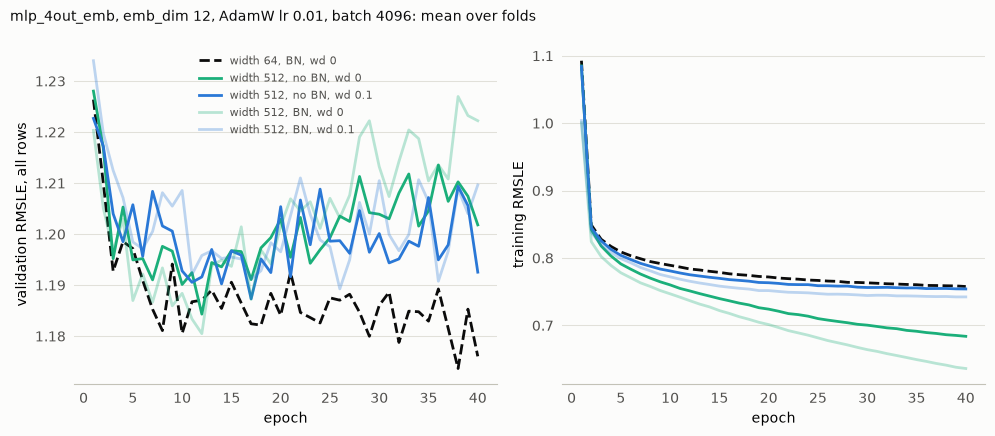

In [5]:
INK, TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS = {0.0: "#1baf7a", 0.1: "#2a78d6"}  # by weight decay

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), facecolor=SURFACE)
for (width, bn, wd), runs in results.groupby(["width", "batch_norm", "weight_decay"]):
    if width == 64:
        style = dict(color=INK, ls="--")
    else:  # the BatchNorm runs of the same width are context, so faint
        style = dict(color=COLORS[wd], ls="-", alpha=0.3 if bn else 1.0)
    for ax, key in zip(axes, ["val_curve", "train_curve"]):
        # mean over folds; a diverged run is shorter
        curve = pd.DataFrame(runs[key].tolist()).mean()
        ax.plot(
            np.arange(1, len(curve) + 1),
            curve,
            lw=2,
            label=f"width {width}, {'BN' if bn else 'no BN'}, wd {wd:g}",
            **style,
        )
for ax, label in zip(axes, ["validation RMSLE, all rows", "training RMSLE"]):
    ax.set(xlabel="epoch", ylabel=label)
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.75)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelcolor=TEXT, length=0, pad=6)
axes[0].legend(frameon=False, fontsize=8, labelcolor=TEXT)
fig.suptitle(
    f"mlp_4out_emb, emb_dim {EMB_DIM}, AdamW lr {LR:g}, batch 4096: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.query("not batch_norm").run_id:
        experiment.client.log_artifact(run_id, FIGURE)